# Explainable NLP Framework for Early Mental Health Risk Detection from Social Media

## Activity 1: Dataset Audit and Initial Analysis

### Objective

The purpose of this notebook is to inspect and understand the dataset selected for the proposed NLP-based mental health risk detection framework.

The dataset will be examined to understand:

- Dataset size and structure
- Available features and target variable
- Missing values
- Duplicate records
- Distribution of mental health risk classes
- Characteristics of the textual data
- Representative examples of social-media text

This initial analysis will help us design the data preprocessing and NLP methodology for the proposed system.

## 1. Import Required Libraries

The following Python libraries are used for dataset loading, data analysis, numerical operations, and visualization.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Dataset

The dataset contains social-media text along with a corresponding mental health risk category.

The `statement` column represents the textual input, while the `status` column represents the target variable used for risk classification.

In [4]:
# Load the dataset
df = pd.read_csv("/content/Reddit_risk_analysis.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (47894, 3)


,Unnamed: 0,statement,status
0,0,oh my gosh,2
1,1,"trouble sleeping, confused mind, restless heart. All out of tune",2
2,2,"All wrong, back off dear, forward doubt. Stay in a restless and restless place",2
3,3,I've shifted my focus to something else but I'm still worried,2
4,4,"I'm restless and restless, it's been a month now, boy. What do you mean?",2


## 3. Dataset Structure

In this step, we examine the number of records, number of attributes, column names, and data types.

Understanding the dataset structure is important before designing the NLP preprocessing pipeline.

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes)

Number of rows: 47894
Number of columns: 3

Column Names:
['Unnamed: 0', 'statement', 'status']

Data Types:


,0
Unnamed: 0,int64
statement,object
status,int64


## 4. Dataset Information

The dataset is inspected for its overall memory usage, non-null values, and data types.

This helps identify whether any columns require conversion or additional preprocessing.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47894 entries, 0 to 47893
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  47894 non-null  int64 
 1   statement   47894 non-null  object
 2   status      47894 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 1.1+ MB


## 5. Missing Value Analysis

Missing or null text records can affect NLP processing and model training.

Therefore, the number of missing values in each column is checked before further processing.

In [7]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:


,0
Unnamed: 0,0
statement,0
status,0



Total missing values: 0


## 6. Duplicate Record Analysis

Duplicate records may introduce bias during model training and evaluation.

Therefore, duplicate rows are identified before preprocessing.

In [8]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## 7. Target Variable Analysis

The `status` column is the target variable for the proposed mental health risk classification task.

We examine the number of records belonging to each target class to understand the class distribution and identify possible class imbalance.

In [9]:
class_counts = df["status"].value_counts().sort_index()

print("Number of records in each status class:")
display(class_counts)

print("\nPercentage distribution:")
class_percentage = (class_counts / len(df)) * 100
display(class_percentage.round(2))

Number of records in each status class:


,count
status,
0,12064
1,16343
2,19487



Percentage distribution:


,count
status,
0,25.19
1,34.12
2,40.69


## 8. Mental Health Risk Class Distribution

The following visualization shows the distribution of records across the available mental health risk classes.

This analysis is important because class imbalance can influence the performance of classification models and will be considered during the later model evaluation stage.


## 8.1 Interpreting the Risk Classes

According to the dataset documentation, the numerical target labels correspond to three mental health risk levels:

- **0 – High Risk:** Explicit suicidal ideation, suicide planning, self-harm intent, or immediate crisis.
- **1 – Low Risk:** General discussions, emotionally neutral posts, or non-crisis mental health conversations.
- **2 – Moderate Risk:** Depression, anxiety, emotional distress, hopelessness, stress, or substance abuse without explicit suicidal intent.

These labels are used for research-oriented risk classification and should not be interpreted as clinical diagnoses.

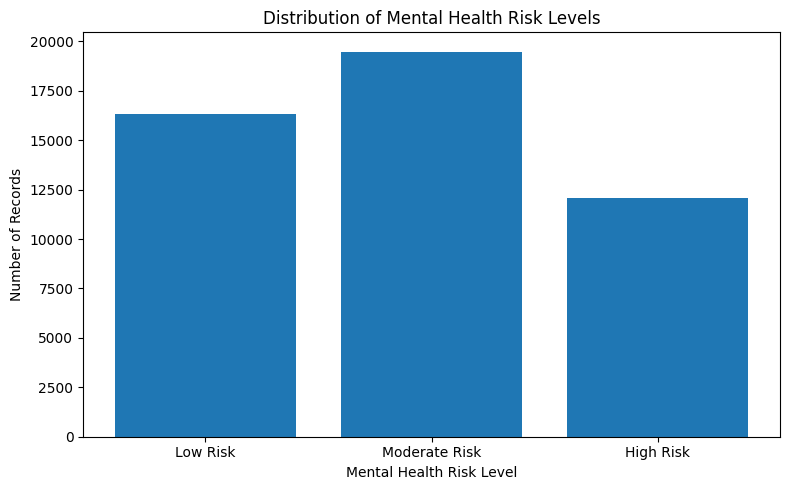

In [15]:
# Map numerical labels to meaningful risk levels
risk_labels = {
    0: "High Risk",
    1: "Low Risk",
    2: "Moderate Risk"
}

risk_counts = df["status"].map(risk_labels).value_counts()

# Keep a meaningful order
risk_order = ["Low Risk", "Moderate Risk", "High Risk"]
risk_counts = risk_counts.reindex(risk_order)

plt.figure(figsize=(8, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values
)

plt.title("Distribution of Mental Health Risk Levels")
plt.xlabel("Mental Health Risk Level")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

## 9. Text Data Inspection

The `statement` column contains the social-media text that will be processed using Natural Language Processing techniques.

A sample of textual records is examined to understand the type of language present in the dataset.

In [11]:
sample_data = df[["statement", "status"]].sample(
    10,
    random_state=42
)

display(sample_data)

,statement,status
32440,@889grapevine Looking forward to the new website,1
10241,"I have done so much to get here. Financially stable, 7/10 in looks, fit and healthy. I thought Id be happy. I am not. I kept trying to think thing...",0
23598,"So I'm unemployed, broke, no car or drivers licence (its suspended due to unpaid tickets). Unemployment ran out a month ago and I have no savings....",2
36930,myconnecticut restaurant called woodntap ha competitive eating tourney round tourney time we place nd,1
1911,"Have you ever panicked, your friend of the opposite sex has changed his attitude towards you, so he looks at you as a girl, not as a friend of the...",1
8807,They say suicide is selfish but if i decide why cannot i have the option to die peacefully after a certain age? is not it selfish for everyone to ...,0
985,how can i forget when i have work,1
15555,"Honestly I do not know where to start. I have had anxiety since I was little, I do not necessarily have a stresser more like if I get stressed it ...",2
40223,xovince pssht i miss u u don t respond to me,1
33446,i m tired depressed and can t go through this alone anymore i haven t been kind to myself i ve taken a pill because i don t want to stay awake eve...,2


## 10. Text Length Analysis

Text length is examined to understand the characteristics of the textual data.

The number of characters in each statement is calculated. This helps identify variations in the length of social-media statements and supports later decisions regarding preprocessing and feature extraction.

In [12]:
# Calculate text length
df["text_length"] = df["statement"].astype(str).str.len()

print("Text length statistics:")
display(df["text_length"].describe())

Text length statistics:


,text_length
count,47894.000000
mean,550.112102
std,805.462318
min,2.000000
25%,71.000000
50%,291.000000
75%,717.000000
max,27588.000000


## 11. Distribution of Text Length

The histogram below visualizes the distribution of statement lengths in the dataset.

Understanding text-length variation is useful when designing the NLP preprocessing and feature extraction pipeline.

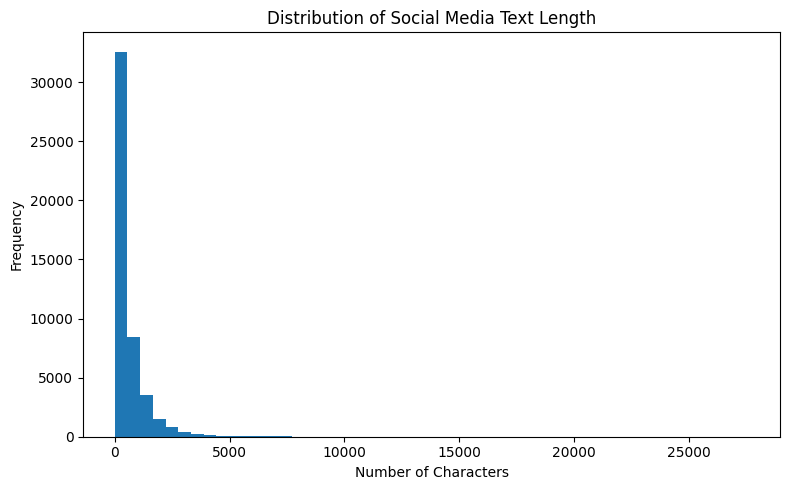

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(df["text_length"], bins=50)

plt.title("Distribution of Social Media Text Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## 12. Preliminary Dataset Quality Summary

The initial audit evaluates the dataset in terms of:

- Number of records
- Number of attributes
- Missing values
- Duplicate records
- Target class distribution
- Text characteristics

These observations will be used to design the preprocessing and NLP methodology for the proposed mental health risk detection framework.

In [14]:
print("========== DATASET AUDIT SUMMARY ==========")
print("Total records       :", len(df))
print("Total columns       :", len(df.columns))
print("Missing values      :", df.isnull().sum().sum())
print("Duplicate rows      :", df.duplicated().sum())
print("Text column         : statement")
print("Target column       : status")
print("Number of classes   :", df["status"].nunique())
print("============================================")

========== DATASET AUDIT SUMMARY ==========
Total records       : 47894
Total columns       : 4
Missing values      : 0
Duplicate rows      : 0
Text column         : statement
Target column       : status
Number of classes   : 3


## 13. NLP Preprocessing Plan

Social-media text is often informal and may contain URLs, mentions, hashtags, punctuation, repeated characters, emojis, and other textual noise.

To prepare the text for NLP-based feature extraction and classification, a systematic preprocessing pipeline is proposed.

The preprocessing pipeline consists of:

1. Removing unnecessary index information
2. Handling missing or empty text
3. Removing duplicate records
4. Converting text to lowercase
5. Removing URLs and unnecessary social-media artifacts
6. Handling punctuation and special characters
7. Tokenization
8. Stop-word handling
9. Lemmatization
10. Producing normalized text for feature extraction

The preprocessing decisions are designed to reduce irrelevant variation while preserving meaningful mental-health-related language.

## 14. Creating a Working Dataset

A separate working copy of the dataset is created so that the original dataset remains unchanged.

The index column is not considered a meaningful NLP feature and will therefore be removed from the working dataset.

In [16]:
# Create a working copy
data = df.copy()

# Remove the unnecessary index column
if "Unnamed: 0" in data.columns:
    data = data.drop(columns=["Unnamed: 0"])

print("Working dataset shape:", data.shape)
print("\nRemaining columns:")
print(data.columns.tolist())

display(data.head())

Working dataset shape: (47894, 3)

Remaining columns:
['statement', 'status', 'text_length']


,statement,status,text_length
0,oh my gosh,2,10
1,"trouble sleeping, confused mind, restless heart. All out of tune",2,64
2,"All wrong, back off dear, forward doubt. Stay in a restless and restless place",2,78
3,I've shifted my focus to something else but I'm still worried,2,61
4,"I'm restless and restless, it's been a month now, boy. What do you mean?",2,72


## 15. Selecting Relevant Columns

For the proposed NLP classification task, the two important fields are:

- `statement` – textual input
- `status` – target risk category

The previously calculated `text_length` field was used only for exploratory analysis and is not part of the primary NLP input.

In [17]:
# Keep only the text and target columns
data = data[["statement", "status"]].copy()

print("Final working columns:")
print(data.columns.tolist())

print("\nWorking dataset shape:", data.shape)

Final working columns:
['statement', 'status']

Working dataset shape: (47894, 2)


## 16. Empty and Missing Text Check

Although the initial dataset audit showed no missing values, empty or whitespace-only statements should also be checked because they do not provide meaningful linguistic information for NLP processing.

In [18]:
# Check for empty or whitespace-only statements
empty_text = data["statement"].astype(str).str.strip().eq("").sum()

print("Empty or whitespace-only statements:", empty_text)

Empty or whitespace-only statements: 0


## 17. Duplicate Text Check

Duplicate textual statements can cause repeated information to appear during model training.

Duplicate records will therefore be identified and removed from the working dataset if necessary.

In [19]:
duplicate_text = data["statement"].duplicated().sum()

print("Duplicate text records:", duplicate_text)

Duplicate text records: 1605


## 18. Basic Text Normalization

The first stage of text normalization converts the text into a consistent format.

The following operations are considered:

- Converting text to lowercase
- Removing URLs
- Removing user mentions
- Reducing unnecessary whitespace

Care is taken not to remove meaningful words that may contribute to mental-health risk identification.

In [20]:
import re

def basic_clean_text(text):
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove user mentions
    text = re.sub(r"@\w+", "", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Demonstrate preprocessing on sample records
sample_text = data["statement"].sample(5, random_state=42)

for original in sample_text:
    cleaned = basic_clean_text(original)

    print("ORIGINAL:")
    print(original)

    print("\nCLEANED:")
    print(cleaned)

    print("\n" + "-"*80 + "\n")

ORIGINAL:
@889grapevine Looking forward to the new website

CLEANED:
looking forward to the new website

--------------------------------------------------------------------------------

ORIGINAL:
I have done so much to get here. Financially stable, 7/10 in looks, fit and healthy. I thought Id be happy. I am not. I kept trying to think things will be different. Thinking that is it, I have made it. But its not enough. I kept being betrayed and used. I feel so dumb and vulnerable. I wish I was anyone but myself. People like me gets sacrificed in movies so other people can live better lives. Is being nice a sin? A sign to other people that you are available to be used and abused? Taken advantage of? I never learn my lesson. I keep giving people second, third chances. I am so tired. Things are no better than they were 10, 15, 20 years ago. Its time to stop trying. Time to end it all. The more you have means you have more to lose. there is no point in any of it. Responsible Suicide

CLEANED

## 19. Tokenization

Tokenization divides each normalized statement into individual words or tokens.

For example:

Original text:

"I feel worried and unable to sleep."

After tokenization:

["i", "feel", "worried", "and", "unable", "to", "sleep"]

Tokenization provides the basic representation required for subsequent NLP preprocessing and feature extraction.

In [21]:
# Install/import NLTK tools
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")

from nltk.tokenize import word_tokenize

# Select a few sample statements
tokenization_samples = data["statement"].sample(5, random_state=42)

for text in tokenization_samples:
    cleaned = basic_clean_text(text)
    tokens = word_tokenize(cleaned)

    print("Original:")
    print(text)

    print("\nTokens:")
    print(tokens)

    print("\n" + "-" * 80 + "\n")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


Original:
@889grapevine Looking forward to the new website

Tokens:
['looking', 'forward', 'to', 'the', 'new', 'website']

--------------------------------------------------------------------------------

Original:
I have done so much to get here. Financially stable, 7/10 in looks, fit and healthy. I thought Id be happy. I am not. I kept trying to think things will be different. Thinking that is it, I have made it. But its not enough. I kept being betrayed and used. I feel so dumb and vulnerable. I wish I was anyone but myself. People like me gets sacrificed in movies so other people can live better lives. Is being nice a sin? A sign to other people that you are available to be used and abused? Taken advantage of? I never learn my lesson. I keep giving people second, third chances. I am so tired. Things are no better than they were 10, 15, 20 years ago. Its time to stop trying. Time to end it all. The more you have means you have more to lose. there is no point in any of it. Responsibl

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


## 20. Stop-word Handling

Common words such as "the", "is", "and", and "to" may contribute less information to traditional text classification models.

Stop-word removal will therefore be evaluated as part of the preprocessing pipeline.

However, words that may influence the interpretation of mental-health-related language should be preserved wherever appropriate.

In [22]:
nltk.download("stopwords")

from nltk.corpus import stopwords

# Load English stop words
stop_words = set(stopwords.words("english"))

# Demonstrate stop-word removal
stopword_samples = data["statement"].sample(5, random_state=42)

for text in stopword_samples:
    cleaned = basic_clean_text(text)
    tokens = word_tokenize(cleaned)

    filtered_tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    print("Original:")
    print(text)

    print("\nTokens:")
    print(tokens)

    print("\nAfter Stop-word Handling:")
    print(filtered_tokens)

    print("\n" + "-" * 80 + "\n")

Original:
@889grapevine Looking forward to the new website

Tokens:
['looking', 'forward', 'to', 'the', 'new', 'website']

After Stop-word Handling:
['looking', 'forward', 'new', 'website']

--------------------------------------------------------------------------------

Original:
I have done so much to get here. Financially stable, 7/10 in looks, fit and healthy. I thought Id be happy. I am not. I kept trying to think things will be different. Thinking that is it, I have made it. But its not enough. I kept being betrayed and used. I feel so dumb and vulnerable. I wish I was anyone but myself. People like me gets sacrificed in movies so other people can live better lives. Is being nice a sin? A sign to other people that you are available to be used and abused? Taken advantage of? I never learn my lesson. I keep giving people second, third chances. I am so tired. Things are no better than they were 10, 15, 20 years ago. Its time to stop trying. Time to end it all. The more you have mea

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## 21. Lemmatization

Lemmatization converts words into their meaningful base or dictionary form.

For example:

- "sleeping" → "sleep"
- "worried" → "worry"
- "feeling" → "feel"

Lemmatization can reduce vocabulary variation while retaining the underlying meaning of words.

The technique will be incorporated into the preprocessing pipeline and evaluated during Activity 2.

In [23]:
# Download required NLTK resources
nltk.download("wordnet")
nltk.download("omw-1.4")

from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

# Demonstrate lemmatization
lemmatization_samples = data["statement"].sample(5, random_state=42)

for text in lemmatization_samples:
    cleaned = basic_clean_text(text)
    tokens = word_tokenize(cleaned)

    filtered_tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    lemmatized_tokens = [
        lemmatizer.lemmatize(word)
        for word in filtered_tokens
    ]

    print("Original:")
    print(text)

    print("\nAfter Tokenization:")
    print(tokens)

    print("\nAfter Stop-word Handling:")
    print(filtered_tokens)

    print("\nAfter Lemmatization:")
    print(lemmatized_tokens)

    print("\n" + "-" * 80 + "\n")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Original:
@889grapevine Looking forward to the new website

After Tokenization:
['looking', 'forward', 'to', 'the', 'new', 'website']

After Stop-word Handling:
['looking', 'forward', 'new', 'website']

After Lemmatization:
['looking', 'forward', 'new', 'website']

--------------------------------------------------------------------------------

Original:
I have done so much to get here. Financially stable, 7/10 in looks, fit and healthy. I thought Id be happy. I am not. I kept trying to think things will be different. Thinking that is it, I have made it. But its not enough. I kept being betrayed and used. I feel so dumb and vulnerable. I wish I was anyone but myself. People like me gets sacrificed in movies so other people can live better lives. Is being nice a sin? A sign to other people that you are available to be used and abused? Taken advantage of? I never learn my lesson. I keep giving people second, third chances. I am so tired. Things are no better than they were 10, 15, 20 ye

## 22. Complete Preprocessing Demonstration

The following example demonstrates the complete transformation of a social-media statement through the proposed NLP preprocessing pipeline.

The processing stages include:

1. Basic text cleaning
2. Tokenization
3. Stop-word handling
4. Lemmatization

This demonstration shows how raw social-media text is transformed into normalized text suitable for downstream NLP feature extraction and classification.

In [24]:
# Select one example statement
example_text = data["statement"].iloc[1]

# Step 1: Basic cleaning
cleaned_text = basic_clean_text(example_text)

# Step 2: Tokenization
tokens = word_tokenize(cleaned_text)

# Step 3: Stop-word handling
filtered_tokens = [
    word for word in tokens
    if word not in stop_words
]

# Step 4: Lemmatization
lemmatized_tokens = [
    lemmatizer.lemmatize(word)
    for word in filtered_tokens
]

# Final normalized text
final_text = " ".join(lemmatized_tokens)

print("========== PREPROCESSING DEMONSTRATION ==========\n")

print("Original Text:")
print(example_text)

print("\nBasic Cleaned Text:")
print(cleaned_text)

print("\nTokenized Text:")
print(tokens)

print("\nAfter Stop-word Handling:")
print(filtered_tokens)

print("\nAfter Lemmatization:")
print(lemmatized_tokens)

print("\nFinal Normalized Text:")
print(final_text)

========== PREPROCESSING DEMONSTRATION ==========

Original Text:
trouble sleeping, confused mind, restless heart. All out of tune

Basic Cleaned Text:
trouble sleeping, confused mind, restless heart. all out of tune

Tokenized Text:
['trouble', 'sleeping', ',', 'confused', 'mind', ',', 'restless', 'heart', '.', 'all', 'out', 'of', 'tune']

After Stop-word Handling:
['trouble', 'sleeping', ',', 'confused', 'mind', ',', 'restless', 'heart', '.', 'tune']

After Lemmatization:
['trouble', 'sleeping', ',', 'confused', 'mind', ',', 'restless', 'heart', '.', 'tune']

Final Normalized Text:
trouble sleeping , confused mind , restless heart . tune


## 23. Proposed NLP Preprocessing Pipeline

The proposed NLP preprocessing pipeline transforms raw social-media text into a normalized representation suitable for feature extraction and mental health risk classification.

### Preprocessing Workflow

**Raw Social-Media Text**

↓  

**Remove Unnecessary Index Information**

↓  

**Missing / Empty Text Check**

↓  

**Duplicate Check**

↓  

**Lowercasing**

↓  

**URL and Mention Handling**

↓  

**Whitespace and Noise Normalization**

↓  

**Tokenization**

↓  

**Stop-word Handling**

↓  

**Lemmatization**

↓  

**Cleaned and Normalized Text**

↓  

**Feature Extraction**

↓  

**Mental Health Risk Classification**

The resulting normalized text will be used for feature extraction and model development during Activity 2.

# CA2: Feature Extraction, Model Building and Evaluation

## Objective

This phase continues the CA1 mental health risk classification project. We will prepare the CA1 dataset for modeling, extract text features, train and compare at least two classification models, and evaluate their results using appropriate metrics.

The model outputs are for educational research only and are not clinical diagnoses or a substitute for professional support.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# The CSV should be in the same folder as this notebook,
# or uploaded to the current Colab session.
df = pd.read_csv("Reddit_risk_analysis.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (47894, 3)
Columns: ['Unnamed: 0', 'statement', 'status']


,Unnamed: 0,statement,status
0,0,oh my gosh,2
1,1,"trouble sleeping, confused mind, restless hear...",2
2,2,"All wrong, back off dear, forward doubt. Stay ...",2
3,3,I've shifted my focus to something else but I'...,2
4,4,"I'm restless and restless, it's been a month n...",2


In [2]:
required_columns = {"statement", "status"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

print("Missing values:")
display(df[["statement", "status"]].isna().sum())

print("\nOriginal label counts:")
display(df["status"].value_counts().sort_index())

print("\nRepeated statements:", df["statement"].duplicated().sum())

Missing values:


statement    0
status       0
dtype: int64


Original label counts:


status
0    12064
1    16343
2    19487
Name: count, dtype: int64


Repeated statements: 1605


In [3]:
# Keep only rows with both text and label.
model_data = df[["statement", "status"]].dropna().copy()
model_data["statement"] = model_data["statement"].astype(str).str.strip()

# Remove empty statements.
model_data = model_data[model_data["statement"] != ""]

# Find statements that have more than one label.
labels_per_statement = model_data.groupby("statement")["status"].nunique()
conflicting_statements = labels_per_statement[labels_per_statement > 1].index

print("Statements with conflicting labels:", len(conflicting_statements))

# Remove every occurrence of those ambiguous statements.
model_data = model_data[
    ~model_data["statement"].isin(conflicting_statements)
].copy()

# Now each statement has one label; keep one copy of each.
model_data = model_data.drop_duplicates(subset="statement").reset_index(drop=True)

print("Rows after preparation:", len(model_data))
print("\nPrepared label counts:")
display(model_data["status"].value_counts().sort_index())

Statements with conflicting labels: 8
Rows after preparation: 46281

Prepared label counts:


status
0    11590
1    16036
2    18655
Name: count, dtype: int64

## Train-Test Split

We split the prepared statements into training and test sets. Stratification keeps the class proportions similar in both sets. The test data is held aside until evaluation.

## Feature Extraction and Models

TF-IDF converts text into numerical features using individual words and two-word phrases. We will compare Logistic Regression and Linear Support Vector Classification. Each model’s feature extraction is fit on the training data only.

In [4]:
X = model_data["statement"]
y = model_data["status"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training examples:", len(X_train))
print("Test examples:", len(X_test))

print("\nTraining label proportions:")
display(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTest label proportions:")
display(y_test.value_counts(normalize=True).sort_index().round(3))

Training examples: 37024
Test examples: 9257

Training label proportions:


status
0    0.250
1    0.346
2    0.403
Name: proportion, dtype: float64


Test label proportions:


status
0    0.250
1    0.347
2    0.403
Name: proportion, dtype: float64

In [5]:
tfidf_settings = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_df": 0.95,
    "max_features": 50000,
    "sublinear_tf": True
}

models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(**tfidf_settings)),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(**tfidf_settings)),
        ("classifier", LinearSVC(
            class_weight="balanced",
            random_state=42
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained.")

Logistic Regression trained.
Linear SVM trained.


In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results).sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Logistic Regression,0.8065,0.7947,0.8022,0.7974,0.8056
1,Linear SVM,0.8021,0.7897,0.7912,0.7902,0.8004



Logistic Regression — classification report
               precision    recall  f1-score   support

    High Risk       0.68      0.72      0.70      2318
     Low Risk       0.89      0.95      0.92      3208
Moderate Risk       0.81      0.74      0.77      3731

     accuracy                           0.81      9257
    macro avg       0.79      0.80      0.80      9257
 weighted avg       0.81      0.81      0.81      9257



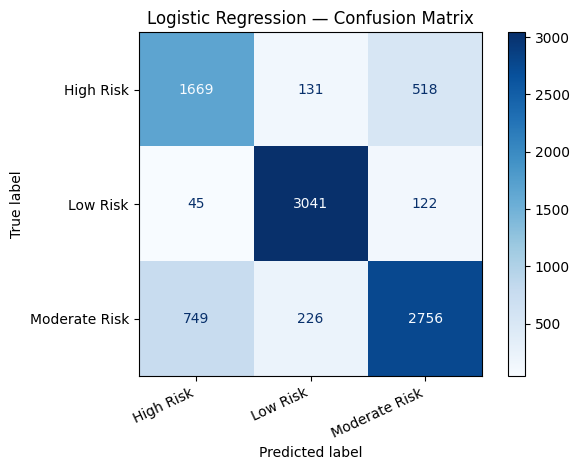


Linear SVM — classification report
               precision    recall  f1-score   support

    High Risk       0.69      0.66      0.67      2318
     Low Risk       0.90      0.95      0.92      3208
Moderate Risk       0.78      0.77      0.77      3731

     accuracy                           0.80      9257
    macro avg       0.79      0.79      0.79      9257
 weighted avg       0.80      0.80      0.80      9257



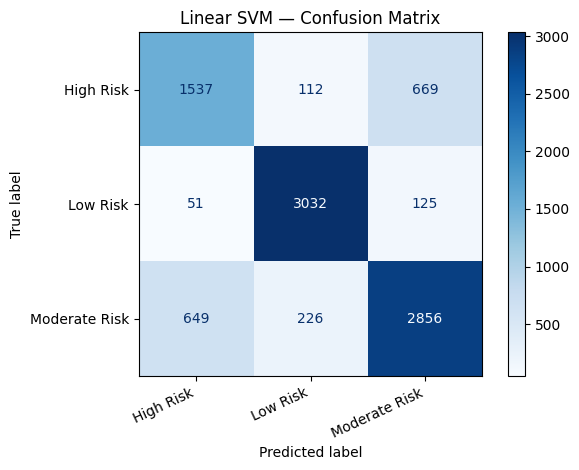

In [7]:
risk_labels = {
    0: "High Risk",
    1: "Low Risk",
    2: "Moderate Risk"
}

label_order = [0, 1, 2]
display_names = [risk_labels[label] for label in label_order]

for name, model in models.items():
    predictions = model.predict(X_test)

    print(f"\n{name} — classification report")
    print(classification_report(
        y_test,
        predictions,
        labels=label_order,
        target_names=display_names,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=label_order,
        display_labels=display_names,
        cmap="Blues",
        values_format="d"
    )
    plt.title(f"{name} — Confusion Matrix")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## Explainability with Logistic Regression

Logistic Regression assigns a weight to each TF-IDF feature for each class. The features with the largest positive weights show which words and phrases most strongly influence the model toward that class. These are patterns learned from this dataset; they do not establish causes or provide clinical explanations.

We will inspect the strongest class-level features and then examine the features contributing to a prediction for text entered for demonstration.

In [8]:
best_model = models["Logistic Regression"]

tfidf = best_model.named_steps["tfidf"]
classifier = best_model.named_steps["classifier"]
feature_names = tfidf.get_feature_names_out()

for class_id, class_weights in zip(classifier.classes_, classifier.coef_):
    print(f"\n{risk_labels[class_id]} — strongest positive features")

    top_indices = np.argsort(class_weights)[-15:][::-1]
    top_features = pd.DataFrame({
        "Feature": feature_names[top_indices],
        "Weight": class_weights[top_indices]
    })
    display(top_features.round(4))


High Risk — strongest positive features


,Feature,Weight
0,bipolar,9.0792
1,avpd,6.7046
2,manic,5.9029
3,suicide,5.7164
4,am,5.1139
5,die,4.4153
6,mania,4.1800
7,suicidal,4.1339
8,myself,3.7956
9,https co,3.7894



Low Risk — strongest positive features


,Feature,Weight
0,url,2.5212
1,ðÿ,1.7736
2,wa,1.7591
3,quot,1.7125
4,eid,1.6457
5,yes,1.6297
6,twitter,1.6108
7,or not,1.6066
8,ptsd,1.4960
9,congratulations,1.4908



Moderate Risk — strongest positive features


,Feature,Weight
0,depression,12.3121
1,anxiety,6.6547
2,restless,6.3838
3,stress,4.6432
4,nervous,4.4781
5,worried,4.3367
6,depressed,4.1531
7,anxious,4.1105
8,wa,3.8206
9,feel,3.3286


In [9]:
def explain_prediction(text, top_n=10):
    predicted_class = best_model.predict([text])[0]

    # Convert the text to the same TF-IDF representation used by the model.
    text_vector = tfidf.transform([text])
    class_index = list(classifier.classes_).index(predicted_class)

    # Show the present terms contributing most toward the predicted class.
    contributions = text_vector.toarray()[0] * classifier.coef_[class_index]
    present_indices = np.flatnonzero(text_vector.toarray()[0])

    top_indices = sorted(
        present_indices,
        key=lambda index: contributions[index],
        reverse=True
    )[:top_n]

    explanation = pd.DataFrame({
        "Feature": feature_names[top_indices],
        "Contribution": contributions[top_indices]
    })

    print("Predicted class:", risk_labels[predicted_class])
    print("This explanation shows model feature contributions, not a clinical assessment.")
    display(explanation.round(4))

# Replace this demonstration sentence with text you choose.
explain_prediction("I have been feeling stressed and unable to sleep lately.")

Predicted class: Moderate Risk
This explanation shows model feature contributions, not a clinical assessment.


,Feature,Contribution
0,stressed,0.5252
1,feeling,0.4738
2,and,0.2714
3,lately,0.1668
4,been,0.1417
5,unable,0.1295
6,unable to,0.1246
7,have been,0.1104
8,stressed and,0.0992
9,have,0.0952


## Project Findings and Limitations

We compare the two models using accuracy, macro F1, and class-level results. Macro F1 gives each class equal weight, which helps reveal performance differences across the risk categories.

The model may confuse High Risk and Moderate Risk statements. Results depend on this dataset and its labels; they do not demonstrate clinical reliability. Predictions must not be used to diagnose a person or make decisions about their care.

In [10]:
best_model_name = results_df.loc[0, "Model"]
best_macro_f1 = results_df.loc[0, "Macro F1"]

print("Best model by macro F1:", best_model_name)
print("Macro F1:", round(best_macro_f1, 4))
print("\nModel comparison:")
display(results_df.round(4))

Best model by macro F1: Logistic Regression
Macro F1: 0.7974

Model comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Logistic Regression,0.8065,0.7947,0.8022,0.7974,0.8056
1,Linear SVM,0.8021,0.7897,0.7912,0.7902,0.8004


## Save the Trained Model

The selected pipeline includes both the TF-IDF feature extraction step and the trained Logistic Regression classifier.

In [11]:
import joblib

joblib.dump(best_model, "mental_health_risk_logistic_regression.joblib")
joblib.dump(risk_labels, "risk_label_mapping.joblib")

print("Saved the model and risk-label mapping.")

Saved the model and risk-label mapping.


In [16]:
# Interactive prediction and feature explanation
user_text = input("Enter a statement to classify: ").strip()

if not user_text:
    print("Please enter some text and run this cell again.")
else:
    # Predict with the trained Logistic Regression pipeline.
    predicted_class = best_model.predict([user_text])[0]
    predicted_label = risk_labels[predicted_class]

    # Get this text's TF-IDF features and their contributions to the
    # predicted class score.
    text_vector = tfidf.transform([user_text]).toarray()[0]
    class_index = list(classifier.classes_).index(predicted_class)
    contributions = text_vector * classifier.coef_[class_index]
    present_indices = np.flatnonzero(text_vector)

    positive_indices = sorted(
        [i for i in present_indices if contributions[i] > 0],
        key=lambda i: contributions[i],
        reverse=True
    )[:10]

    negative_indices = sorted(
        [i for i in present_indices if contributions[i] < 0],
        key=lambda i: contributions[i]
    )[:10]

    print("\nPredicted category:", predicted_label)
    print(
        "\nWhy: These are text features that influenced the model's score. "
        "They are learned associations, not clinical reasons or a diagnosis."
    )

    if positive_indices:
        print("\nFeatures pushing toward the predicted category:")
        display(pd.DataFrame({
            "Feature": [feature_names[i] for i in positive_indices],
            "Contribution": [contributions[i] for i in positive_indices]
        }).round(4))
    else:
        print("\nNo clear positive text-feature contributions were found.")

    if negative_indices:
        print("\nFeatures pushing away from the predicted category:")
        display(pd.DataFrame({
            "Feature": [feature_names[i] for i in negative_indices],
            "Contribution": [contributions[i] for i in negative_indices]
        }).round(4))

    print(
        "\nPrecaution: This is an experimental model trained on a specific "
        "dataset. It can be wrong, may miss important context, and must not "
        "be used to diagnose someone or make decisions about their care. "
        "If this text reflects an immediate safety concern, contact a trusted "
        "person or local emergency or crisis support."
    )

Enter a statement to classify:  I am thinking about hurting myself and need help staying safe right now



Predicted category: High Risk

Why: These are text features that influenced the model's score. They are learned associations, not clinical reasons or a diagnosis.

Features pushing toward the predicted category:


,Feature,Contribution
0,am,0.4899
1,myself,0.4499
2,right now,0.1900
3,am thinking,0.1781
4,hurting,0.1359
5,hurting myself,0.1182
6,need,0.1136
7,and,0.1132
8,about,0.0993
9,need help,0.0944



Features pushing away from the predicted category:


,Feature,Contribution
0,and need,-0.1229
1,myself and,-0.1135



Precaution: This is an experimental model trained on a specific dataset. It can be wrong, may miss important context, and must not be used to diagnose someone or make decisions about their care. If this text reflects an immediate safety concern, contact a trusted person or local emergency or crisis support.


## Visual Summary of Data and Model Performance

The following dashboard summarizes the prepared class distribution and the test-set performance of both models. The confusion matrix is row-normalized so it shows the proportion of each actual class assigned to each predicted class.

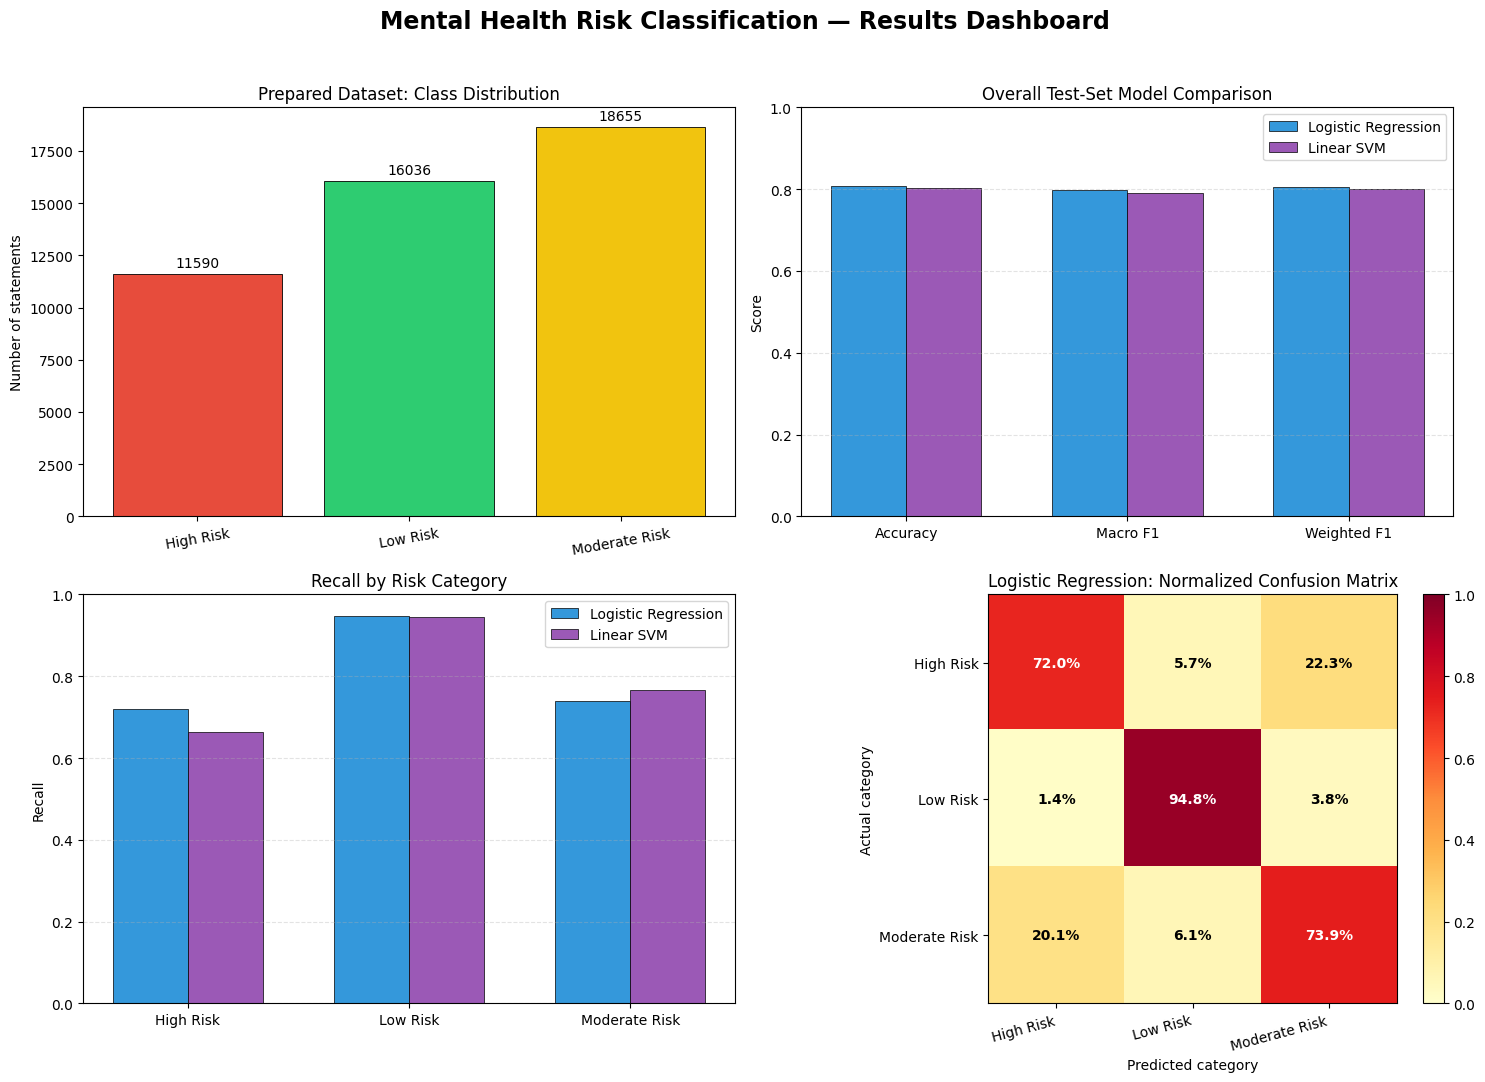

In [17]:
from sklearn.metrics import confusion_matrix, recall_score

# Consistent class order and colors
class_order = [0, 1, 2]
class_names = [risk_labels[i] for i in class_order]
risk_colors = ["#e74c3c", "#2ecc71", "#f1c40f"]  # High, Low, Moderate

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle(
    "Mental Health Risk Classification — Results Dashboard",
    fontsize=17,
    fontweight="bold"
)

# 1. Prepared dataset class distribution
class_counts = model_data["status"].value_counts().reindex(class_order)

bars = axes[0, 0].bar(
    class_names,
    class_counts.values,
    color=risk_colors,
    edgecolor="black",
    linewidth=0.6
)
axes[0, 0].set_title("Prepared Dataset: Class Distribution")
axes[0, 0].set_ylabel("Number of statements")
axes[0, 0].bar_label(bars, fmt="%.0f", padding=3)
axes[0, 0].tick_params(axis="x", rotation=10)

# 2. Overall model metric comparison
metric_names = ["Accuracy", "Macro F1", "Weighted F1"]
model_names = results_df["Model"].tolist()
x = np.arange(len(metric_names))
width = 0.34
metric_colors = ["#3498db", "#9b59b6"]

for i, model_name in enumerate(model_names):
    row = results_df[results_df["Model"] == model_name].iloc[0]
    values = [row[m] for m in metric_names]
    axes[0, 1].bar(
        x + (i - (len(model_names) - 1) / 2) * width,
        values,
        width,
        label=model_name,
        color=metric_colors[i],
        edgecolor="black",
        linewidth=0.5
    )

axes[0, 1].set_title("Overall Test-Set Model Comparison")
axes[0, 1].set_ylabel("Score")
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(metric_names)
axes[0, 1].set_ylim(0, 1)
axes[0, 1].legend()
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.35)

# 3. Recall for each class and model
for i, model_name in enumerate(model_names):
    predictions = models[model_name].predict(X_test)
    class_recalls = recall_score(
        y_test,
        predictions,
        labels=class_order,
        average=None,
        zero_division=0
    )
    axes[1, 0].bar(
        x + (i - (len(model_names) - 1) / 2) * width,
        class_recalls,
        width,
        label=model_name,
        color=metric_colors[i],
        edgecolor="black",
        linewidth=0.5
    )

axes[1, 0].set_title("Recall by Risk Category")
axes[1, 0].set_ylabel("Recall")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(class_names)
axes[1, 0].set_ylim(0, 1)
axes[1, 0].legend()
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.35)

# 4. Row-normalized confusion matrix for Logistic Regression
lr_predictions = models["Logistic Regression"].predict(X_test)
cm = confusion_matrix(
    y_test,
    lr_predictions,
    labels=class_order,
    normalize="true"
)

image = axes[1, 1].imshow(cm, cmap="YlOrRd", vmin=0, vmax=1)
axes[1, 1].set_title("Logistic Regression: Normalized Confusion Matrix")
axes[1, 1].set_xlabel("Predicted category")
axes[1, 1].set_ylabel("Actual category")
axes[1, 1].set_xticks(range(len(class_names)))
axes[1, 1].set_yticks(range(len(class_names)))
axes[1, 1].set_xticklabels(class_names, rotation=15, ha="right")
axes[1, 1].set_yticklabels(class_names)

for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        text_color = "white" if cm[row, col] > 0.55 else "black"
        axes[1, 1].text(
            col, row, f"{cm[row, col]:.1%}",
            ha="center", va="center",
            color=text_color, fontweight="bold"
        )

fig.colorbar(image, ax=axes[1, 1], fraction=0.046, pad=0.04)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# CA2: Work Summary, Findings, and Conclusion

## Project Objective

This project continues the CA1 study of classifying social media statements into three dataset-defined mental health risk categories: **High Risk (0), Low Risk (1), and Moderate Risk (2)**. The goal was to build and evaluate text classification models and inspect which text features influenced their predictions. These categories and predictions are for academic analysis only; they are not clinical diagnoses or recommendations.

## Data Preparation

The CA1 dataset contained **47,894 rows** with `statement` and `status` fields, along with an index column. We selected the statement text as the input and status as the target label. The original class counts were:

- High Risk (0): 12,064
- Low Risk (1): 16,343
- Moderate Risk (2): 19,487

There were no missing values in the text or target columns. We found **1,605 repeated statements** and **8 statements associated with conflicting labels**. To avoid ambiguous examples and reduce the chance of identical statements appearing in both training and test data, we removed all statements with conflicting labels and kept one copy of each remaining statement. This left **46,281 unique statements**:

- High Risk (0): 11,590
- Low Risk (1): 16,036
- Moderate Risk (2): 18,655

We then split the data into training and test sets using an 80:20 stratified split. The training set contained **37,024 statements** and the test set contained **9,257 statements**. Stratification kept the proportions of the three classes approximately equal in both sets.

## Feature Extraction

Machine learning models require numerical input, so we used **TF-IDF** (Term Frequency–Inverse Document Frequency) to convert the statements into numerical features. We included single words and two-word phrases (unigrams and bigrams). This lets the models use both individual terms and short phrases when making predictions.

TF-IDF was included inside each model pipeline. This ensures the vocabulary and feature weights are learned from the training data rather than the test data, reducing information leakage.

## Models and Why We Chose Them

We trained and compared two supervised text classification models:

1. **Logistic Regression** — a strong baseline for text classification that is efficient on sparse TF-IDF features. Its feature weights can also be inspected to see which words and phrases are associated with each predicted class.
2. **Linear Support Vector Machine (Linear SVM)** — a second common model for high-dimensional text data. It provides a useful comparison because it learns class boundaries differently from Logistic Regression.

Both models used class weighting to account for the unequal class counts. We compared them using accuracy, macro precision, macro recall, macro F1, and weighted F1. Macro F1 gives equal importance to each class, while weighted F1 accounts for the number of test examples in each class.

## Results

| Model | Accuracy | Macro Precision | Macro Recall | Macro F1 | Weighted F1 |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.8065 | 0.7947 | 0.8022 | 0.7974 | 0.8056 |
| Linear SVM | 0.8021 | 0.7897 | 0.7912 | 0.7902 | 0.8004 |

Logistic Regression performed slightly better across all reported overall metrics. Its classification report showed:

- **High Risk:** precision 0.68, recall 0.72, F1-score 0.70
- **Low Risk:** precision 0.89, recall 0.95, F1-score 0.92
- **Moderate Risk:** precision 0.81, recall 0.74, F1-score 0.77

Linear SVM showed:

- **High Risk:** precision 0.69, recall 0.66, F1-score 0.67
- **Low Risk:** precision 0.90, recall 0.95, F1-score 0.92
- **Moderate Risk:** precision 0.78, recall 0.77, F1-score 0.77

The confusion matrices showed that both models classified Low Risk statements most reliably. Logistic Regression correctly identified **1,669 of 2,318 High Risk** test statements, while Linear SVM correctly identified **1,537**. Both models confused some High Risk statements with Moderate Risk statements: **518** for Logistic Regression and **669** for Linear SVM.

## Explainability

We inspected the Logistic Regression feature weights to identify words and phrases that most strongly influenced predictions for each class. We also demonstrated a prediction on an entered example and displayed the text features contributing most toward its predicted class.

For the example sentence, the model predicted **Moderate Risk**. The largest displayed positive contributions included “stressed” and “feeling.” These are model associations learned from the dataset; they do not explain a person’s mental state or establish why someone wrote a statement.

## Overall Findings and Conclusion

On this dataset and split, Logistic Regression was the stronger overall model, with a macro F1-score of **0.7974** and a High Risk recall of **0.72**. Linear SVM achieved a macro F1-score of **0.7902** and a High Risk recall of **0.66**. We therefore selected Logistic Regression as the preferred model for this project and used its feature weights for the explainability demonstration.

The results also reveal an important limitation: performance varied by class. Both models performed strongly on Low Risk statements, but distinguishing High Risk from Moderate Risk was more difficult. The confusion matrices show that these two categories were sometimes mistaken for one another. The models should therefore be understood as experimental classifiers for this dataset, not as reliable clinical screening or decision-making tools.

Overall, the CA2 work completed an NLP classification pipeline: preparing the CA1 data, extracting TF-IDF features, training two models, comparing their performance, inspecting their errors, and demonstrating feature-based explanations. Further work could investigate alternative preprocessing choices, model settings, or additional data, with particular attention to improving High Risk detection and evaluating the system on data from a separate source.